In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Load dataset
df = pd.read_csv(r"../data/traffic_intelligence_dataset_1lakh.csv")


# Display first 5 rows
df.head()

,record_id,timestamp,location_name,latitude,longitude,road_type,lane_count,day_of_week,hour,is_weekend,...,signal_status,public_transport_delay_min,pollution_index_aqi,event_nearby,construction_work,accident_reported,accident_severity,prev_hour_congestion,congestion_level,target_congestion_next_hour
0,1,01-01-2024 00:04,Wakad Bridge,18.598795,73.763022,Highway,6,0,0,0,...,Working,3.6,55,0,1,0,NaN,Low,Low,Low
1,2,01-01-2024 00:09,Magarpatta Rd,18.515726,73.927038,Local,2,0,0,0,...,Working,0.4,59,0,0,0,NaN,Low,Low,Low
2,3,01-01-2024 00:11,Kharadi IT Park Rd,18.544116,73.934890,Highway,6,0,0,0,...,Working,1.6,67,0,0,0,NaN,Low,Low,Low
3,4,01-01-2024 00:15,Kothrud Depot,18.507846,73.801938,Local,2,0,0,0,...,Working,0.0,72,0,0,0,NaN,Low,Low,Low
4,5,01-01-2024 00:16,Swargate Signal,18.499092,73.859743,Local,2,0,0,0,...,Working,6.3,60,1,0,0,NaN,Low,Low,Low


# Can we predict next-hour congestion?

In [10]:
df['target_congestion_next_hour'].value_counts()

target_congestion_next_hour
Low       42222
Medium    24227
Severe    21426
High      12125
Name: count, dtype: int64

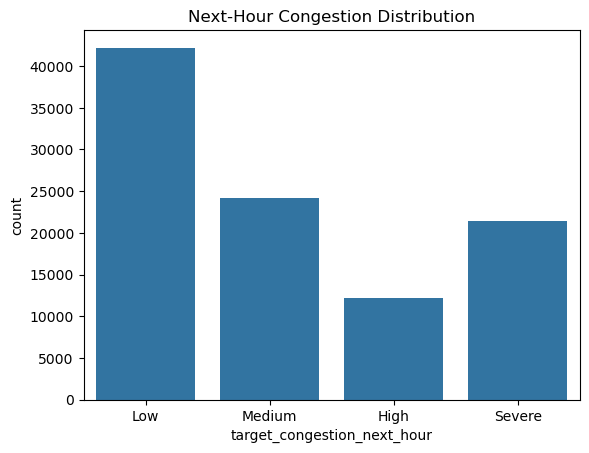

In [11]:
sns.countplot(
    data=df,
    x='target_congestion_next_hour'
)

plt.title('Next-Hour Congestion Distribution')
plt.show()

# Current vs Next-Hour Congestion

In [12]:
transition = pd.crosstab(
    df['congestion_level'],
    df['target_congestion_next_hour'],
    normalize='index'
) * 100

print(transition.round(2))

target_congestion_next_hour   High    Low  Medium  Severe
congestion_level                                         
High                         73.16   0.00   15.54   11.30
Low                           0.00  89.33   10.67    0.00
Medium                        9.02  12.65   78.33    0.00
Severe                        7.99   0.00    0.00   92.01


# Next-Hour Congestion by Hour

In [14]:
hour_target = pd.crosstab(
    df['hour'],
    df['target_congestion_next_hour'],
    normalize='index'
) * 100

print(hour_target.round(2))

target_congestion_next_hour   High    Low  Medium  Severe
hour                                                     
0                             0.05  90.78    9.17    0.00
1                             0.02  90.81    9.17    0.00
2                             0.00  91.00    9.00    0.00
3                             0.07  91.30    8.63    0.00
4                             0.07  88.10   11.80    0.02
5                             0.24  78.77   21.00    0.00
6                             5.63  41.02   53.17    0.17
7                            36.15   8.96   36.39   18.50
8                            22.19   1.43   16.24   60.14
9                            18.24   1.47   12.59   67.70
10                           24.56   4.31   19.53   51.59
11                           29.10  17.56   43.03   10.31
12                            3.57  52.69   43.64    0.10
13                            0.15  80.68   19.18    0.00
14                            0.41  74.61   24.99    0.00
15            

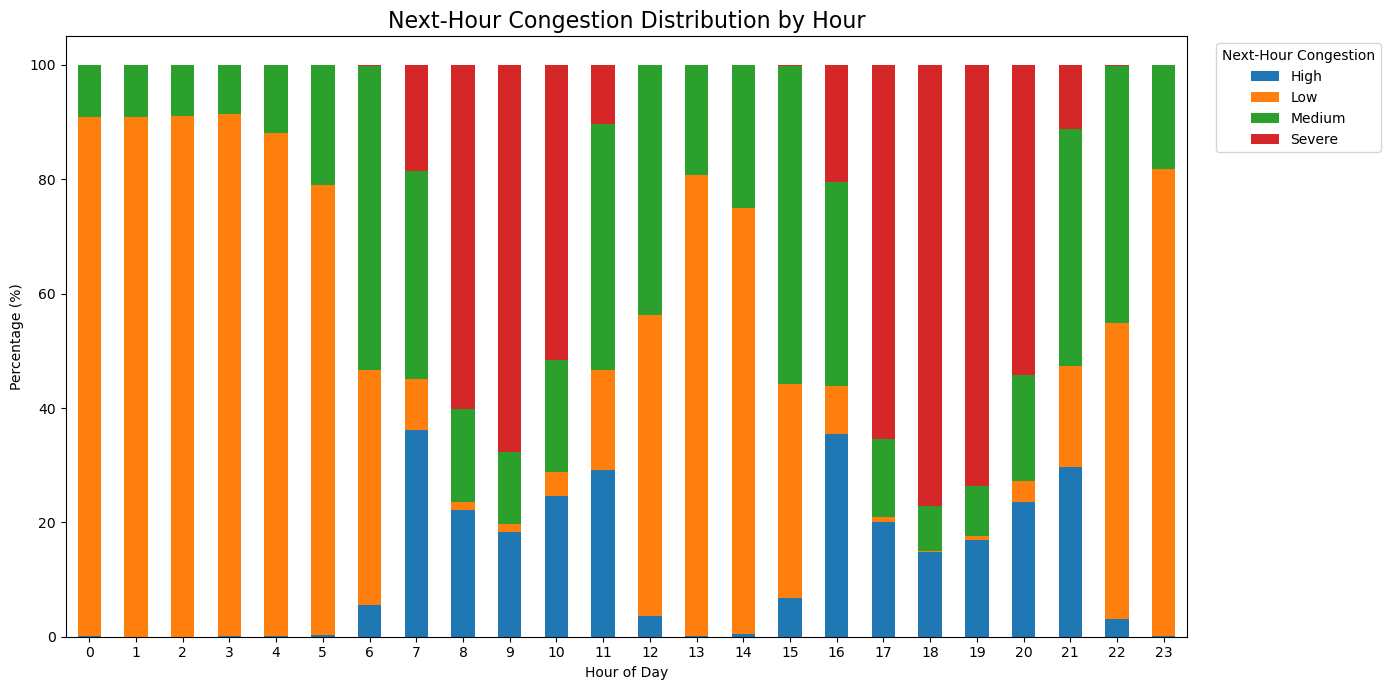

In [18]:
# ==========================================
# STACKED BAR CHART
# Next-Hour Congestion by Hour
# ==========================================

hour_target.plot(
    kind='bar',
    stacked=True,
    figsize=(14, 7)
)

plt.title(
    'Next-Hour Congestion Distribution by Hour',
    fontsize=16
)

plt.xlabel('Hour of Day')
plt.ylabel('Percentage (%)')

plt.xticks(rotation=0)

plt.legend(
    title='Next-Hour Congestion',
    bbox_to_anchor=(1.02, 1),
    loc='upper left'
)

plt.tight_layout()

plt.show()

#  the highest-risk hours

In [22]:
# ==========================================
# TOP 5 HIGH-RISK HOURS
# ==========================================

# Create High/Severe vs Low/Medium category
df['next_hour_high_risk'] = np.where(
    df['target_congestion_next_hour'].isin(['High', 'Severe']),
    'High/Severe',
    'Low/Medium'
)

# Calculate percentage for each hour
risk_by_hour = pd.crosstab(
    df['hour'],
    df['next_hour_high_risk'],
    normalize='index'
) * 100

# Sort High/Severe hours from highest to lowest
risk_hours = risk_by_hour['High/Severe'].sort_values(
    ascending=False
)

# Display top 5
print("Top 5 high-risk hours:")
print(risk_hours.head(5).round(2))

Top 5 high-risk hours:
hour
18    91.92
19    90.61
9     85.94
17    85.34
8     82.33
Name: High/Severe, dtype: float64


# Prediction Model

In [37]:
features = [
    "vehicle_count",
    "occupancy_percent",
    "avg_speed_kmph",
    "travel_time_index",
    "public_transport_delay_min",
    "pollution_index_aqi",
    "hour",
    "lane_count",
    "is_weekend",
    "is_holiday",
    "event_nearby",
    "construction_work",
    "accident_reported"
]

print("Number of features:", len(features))

Number of features: 13


In [38]:
target = "target_congestion_next_hour"

print("Target:", target)
print(df[target].value_counts())

Target: target_congestion_next_hour
target_congestion_next_hour
Low       42222
Medium    24227
Severe    21426
High      12125
Name: count, dtype: int64


In [39]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, classification_report

In [40]:


X = df[features].copy()

y = df[target].copy()

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (100000, 13)
y shape: (100000,)


In [41]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (80000, 13)
Testing data: (20000, 13)


In [43]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

print("Random Forest model trained successfully!")

Random Forest model trained successfully!


In [44]:
y_pred = model.predict(X_test)

print("Predictions completed!")

Predictions completed!


In [45]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", round(accuracy * 100, 2), "%")

Model Accuracy: 85.96 %


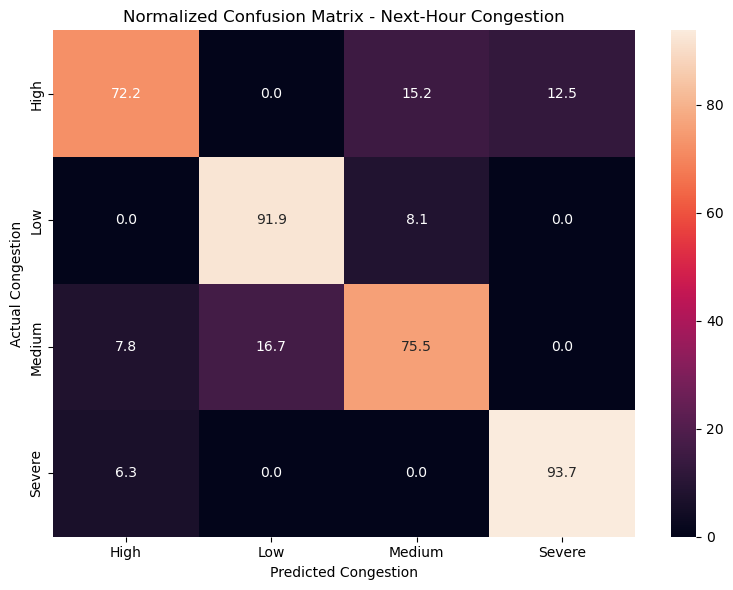

In [49]:
from sklearn.metrics import confusion_matrix

# ==========================================
# NORMALIZED CONFUSION MATRIX
# ==========================================

cm_percent = confusion_matrix(
    y_test,
    y_pred,
    normalize='true'
) * 100

class_names = sorted(df[target].dropna().unique())

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm_percent,
    annot=True,
    fmt=".1f",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Normalized Confusion Matrix - Next-Hour Congestion")
plt.xlabel("Predicted Congestion")
plt.ylabel("Actual Congestion")

plt.tight_layout()
plt.show()


In [50]:
feature_importance = pd.DataFrame({
    "Feature": features,
    "Importance": model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)

                       Feature  Importance
1            occupancy_percent    0.350859
0                vehicle_count    0.166634
3            travel_time_index    0.157826
4   public_transport_delay_min    0.089093
2               avg_speed_kmph    0.072513
5          pollution_index_aqi    0.068083
6                         hour    0.064614
7                   lane_count    0.012340
8                   is_weekend    0.006584
11           construction_work    0.003899
10                event_nearby    0.003669
9                   is_holiday    0.002191
12           accident_reported    0.001694


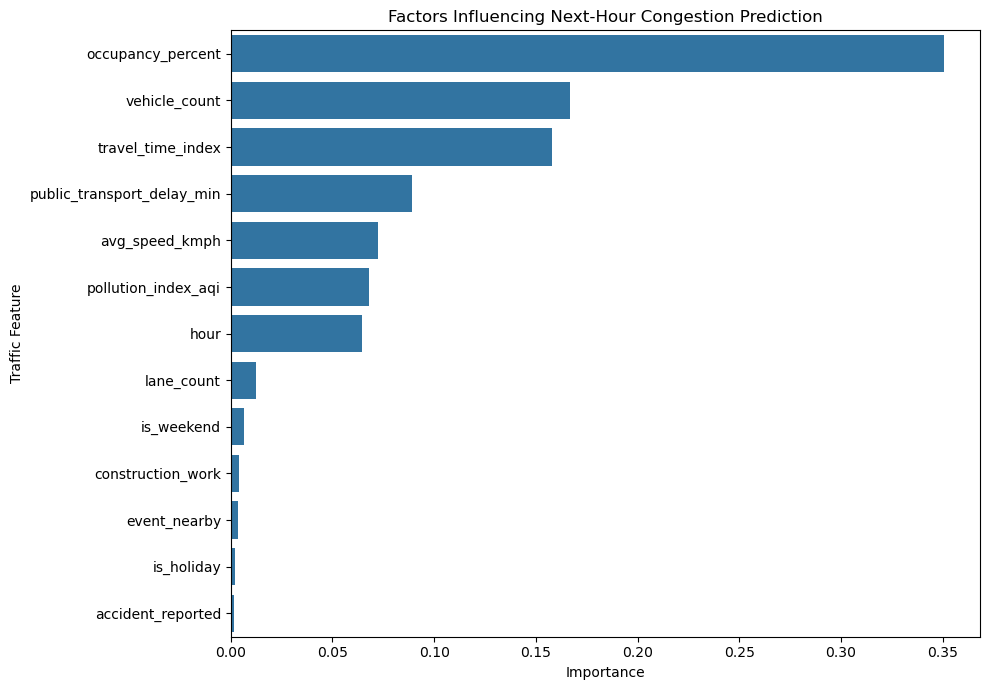

In [51]:
plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance,
    x="Importance",
    y="Feature"
)

plt.title("Factors Influencing Next-Hour Congestion Prediction")
plt.xlabel("Importance")
plt.ylabel("Traffic Feature")

plt.tight_layout()
plt.show()